In [ ]:
# ============================================
# AML PBL PROJECT
# HEALTHCARE DECISION SUPPORT SYSTEM
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load Breast Cancer Wisconsin Dataset

data = load_breast_cancer()

# Convert dataset into DataFrame
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Add target column
df['diagnosis'] = data.target

# Display dataset
print("Dataset Loaded Successfully!")
print("=" * 60)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nTarget Classes:")
print(data.target_names)

print("\nClass Distribution:")
print(df['diagnosis'].value_counts())

Dataset Loaded Successfully!
Dataset Shape: (569, 31)

First 5 Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Target Classes:
['malignant' 'benign']

Class Distribution:
diagnosis
1    357
0    212
Name: count, dtype: int64


In [ ]:
# Dataset information

print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df['diagnosis'].value_counts().rename(
    index={0: 'Malignant', 1: 'Benign'}
))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smooth

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Missing Values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64

Duplicate Records:
0

Target Distribution:
diagnosis
Benign       357


In [ ]:
# Separate input features and target

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Handle missing values
imputer = SimpleImputer(strategy='median')

X_clean = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

# Check missing values after cleaning
print("Missing values after cleaning:",
      X_clean.isnull().sum().sum())

# Check duplicate records
print("Duplicate records:", X_clean.duplicated().sum())

print("\nPreprocessing completed successfully!")

print("\nFeature Shape:", X_clean.shape)
print("Target Shape:", y.shape)

Missing values after cleaning: 0
Duplicate records: 0

Preprocessing completed successfully!

Feature Shape: (569, 30)
Target Shape: (569,)


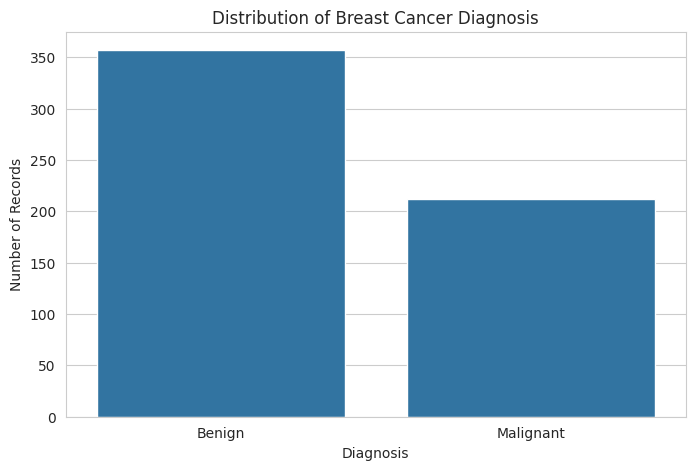

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


In [ ]:
# Diagnosis distribution

diagnosis_counts = y.map({
    0: 'Malignant',
    1: 'Benign'
}).value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=diagnosis_counts.index,
    y=diagnosis_counts.values
)

plt.title("Distribution of Breast Cancer Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")

plt.show()

print(diagnosis_counts)

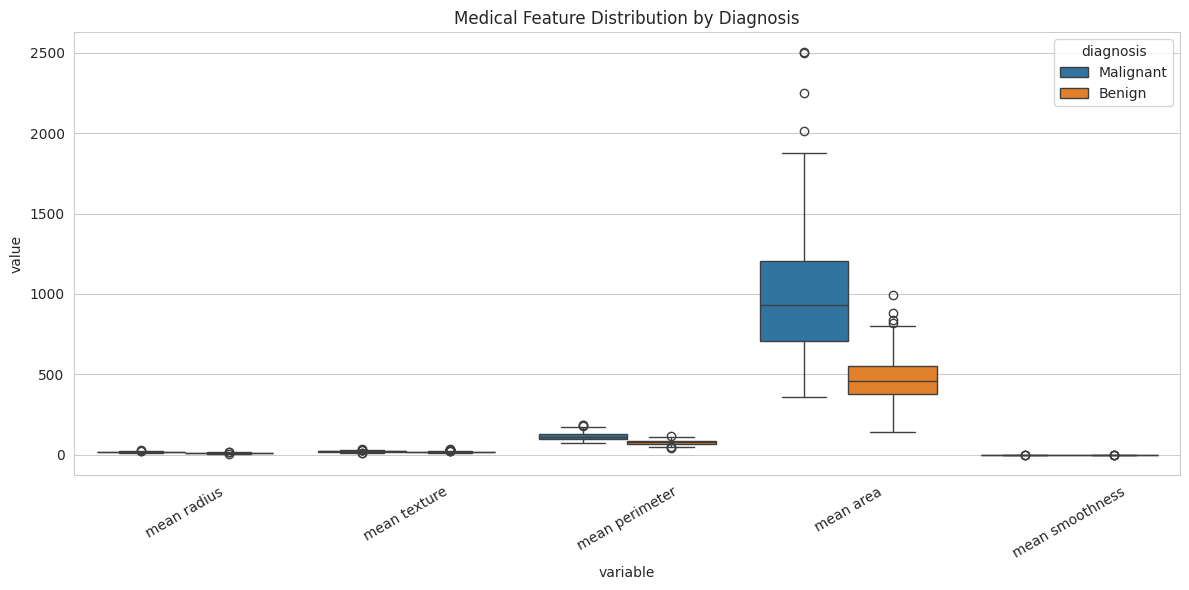

In [ ]:
# Distribution of important medical features

important_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness'
]

df_melted = df.melt(
    id_vars='diagnosis',
    value_vars=important_features
)

df_melted['diagnosis'] = df_melted['diagnosis'].map({
    0: 'Malignant',
    1: 'Benign'
})

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_melted,
    x='variable',
    y='value',
    hue='diagnosis'
)

plt.title("Medical Feature Distribution by Diagnosis")
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

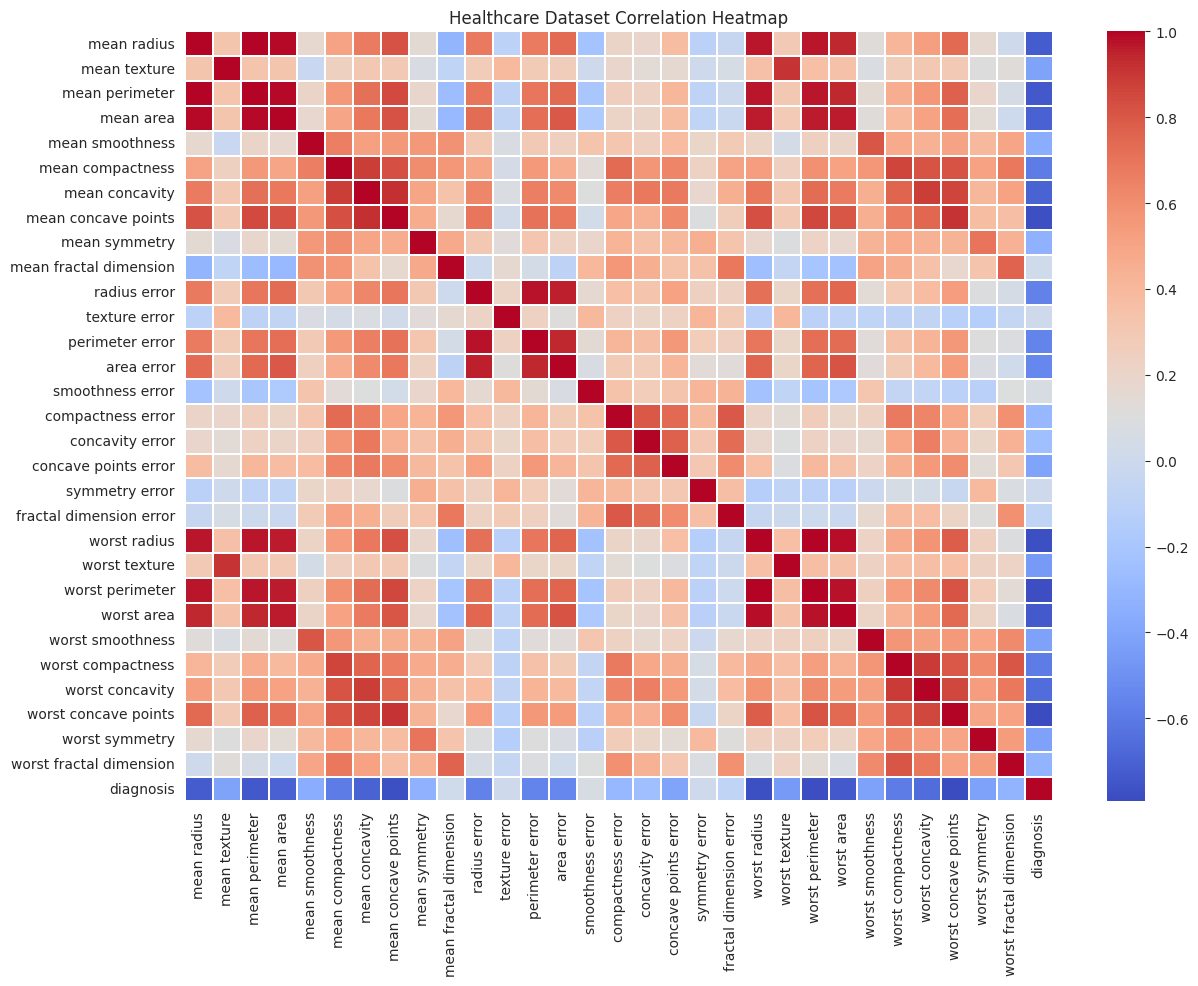

In [ ]:
# Correlation analysis

plt.figure(figsize=(14, 10))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    linewidths=0.3
)

plt.title("Healthcare Dataset Correlation Heatmap")

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data Splitting Completed!")
print("=" * 50)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("Training Features:", X_train.shape[1])

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Data Splitting Completed!
Training Samples: 455
Testing Samples: 114
Training Features: 30

Training Target Distribution:
diagnosis
1    285
0    170
Name: count, dtype: int64

Testing Target Distribution:
diagnosis
1    72
0    42
Name: count, dtype: int64


In [ ]:
# Define machine learning models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Support Vector Machine": SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    )
}

# Train each model using a preprocessing pipeline

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll machine learning models trained!")

Logistic Regression trained successfully!
Random Forest trained successfully!
Support Vector Machine trained successfully!

All machine learning models trained!


In [ ]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 0]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, pos_label=0
        ),
        'Recall': recall_score(
            y_test, y_pred, pos_label=0
        ),
        'F1 Score': f1_score(
            y_test, y_pred, pos_label=0
        ),
        'ROC-AUC': roc_auc_score(
            (y_test == 0).astype(int), y_prob
        )
    })

results_df = pd.DataFrame(results)

print("MACHINE LEARNING MODEL COMPARISON")
print("=" * 70)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)

MACHINE LEARNING MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9954
1,Random Forest,0.9561,0.9512,0.9286,0.9398,0.9932
2,Support Vector Machine,0.9825,0.9762,0.9762,0.9762,0.9950


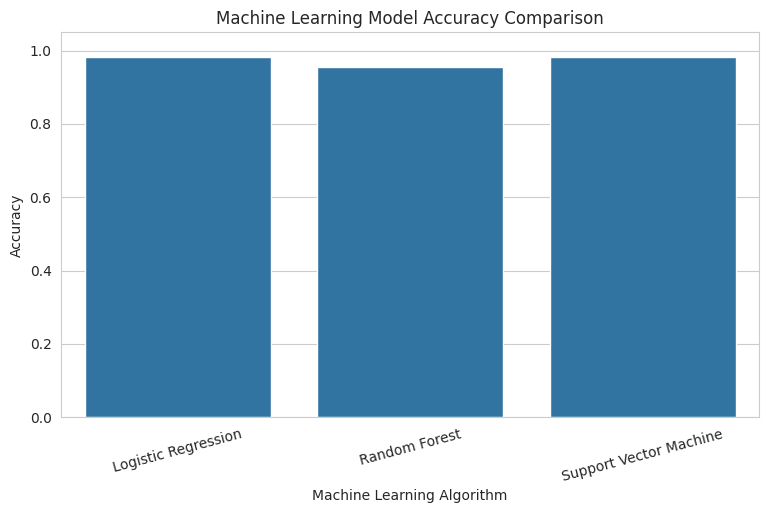

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

plt.show()

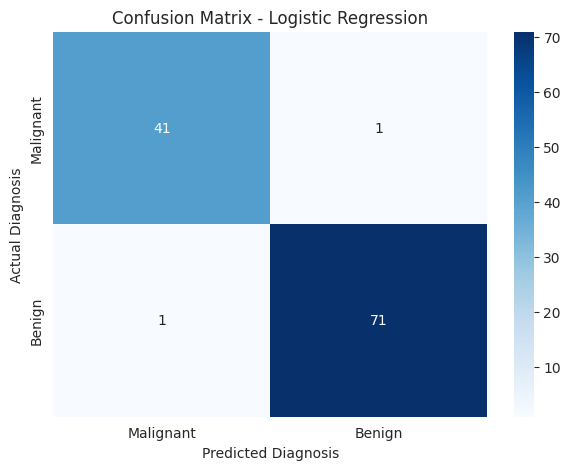

Selected Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [ ]:
# Select best model based on ROC-AUC

best_model_name = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")

plt.show()

print("Selected Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Malignant', 'Benign']
))

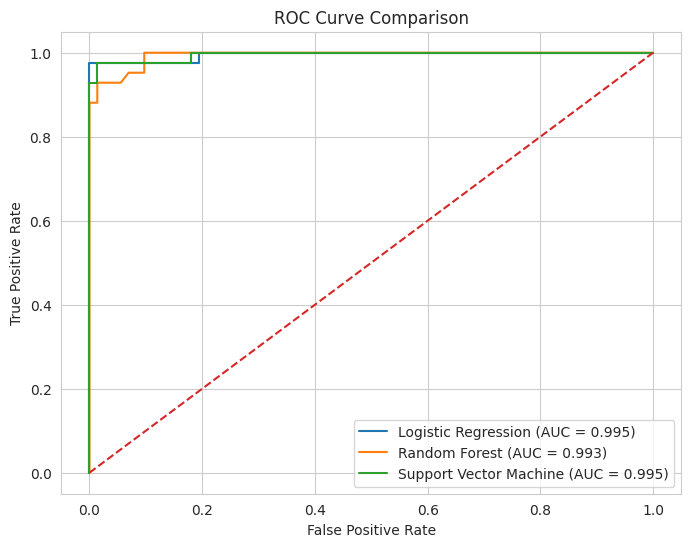

In [ ]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_test)[:, 0]

    fpr, tpr, thresholds = roc_curve(
        (y_test == 0).astype(int),
        probabilities
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--')

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

In [ ]:
def predict_health_risk(patient_data):

    # Convert patient input into DataFrame
    patient_df = pd.DataFrame(
        [patient_data],
        columns=X_train.columns
    )

    # Predict diagnosis
    prediction = best_model.predict(patient_df)[0]

    # Get prediction probabilities
    probabilities = best_model.predict_proba(
        patient_df
    )[0]

    malignant_probability = probabilities[0] * 100
    benign_probability = probabilities[1] * 100

    # Display results
    print("\n" + "=" * 55)
    print("HEALTHCARE DECISION SUPPORT SYSTEM")
    print("=" * 55)

    if prediction == 0:
        print("Predicted Diagnosis: MALIGNANT")
        print("Risk Category: HIGHER MODEL-ESTIMATED RISK")
    else:
        print("Predicted Diagnosis: BENIGN")
        print("Risk Category: LOWER MODEL-ESTIMATED RISK")

    print(f"\nMalignant Probability: {malignant_probability:.2f}%")
    print(f"Benign Probability: {benign_probability:.2f}%")

    print("\nRecommendation:")
    print("Consult a qualified healthcare professional")
    print("for clinical interpretation and further evaluation.")

    print("=" * 55)

    return {
        'prediction': prediction,
        'malignant_probability': malignant_probability,
        'benign_probability': benign_probability
    }


# Example patient measurement from held-out test data
sample_patient = X_test.iloc[0].to_dict()

prediction_result = predict_health_risk(sample_patient)


HEALTHCARE DECISION SUPPORT SYSTEM
Predicted Diagnosis: MALIGNANT
Risk Category: HIGHER MODEL-ESTIMATED RISK

Malignant Probability: 100.00%
Benign Probability: 0.00%

Recommendation:
Consult a qualified healthcare professional
for clinical interpretation and further evaluation.


In [ ]:
# Save the best trained model

joblib.dump(
    best_model,
    'healthcare_decision_support_model.pkl'
)

print("Model saved successfully!")

# Load the saved model
loaded_model = joblib.load(
    'healthcare_decision_support_model.pkl'
)

print("Model loaded successfully!")

# Verify model prediction
test_prediction = loaded_model.predict(X_test.iloc[:5])

print("\nSample Predictions:")
print(test_prediction)

Model saved successfully!
Model loaded successfully!

Sample Predictions:
[0 1 0 1 0]


In [ ]:
# Save model comparison results
results_df.to_csv(
    'healthcare_model_comparison.csv',
    index=False
)

# Save dataset
df.to_csv(
    'healthcare_processed_dataset.csv',
    index=False
)

print("Project files exported successfully!")

# Download files from Google Colab
from google.colab import files

files.download('healthcare_decision_support_model.pkl')
files.download('healthcare_model_comparison.csv')
files.download('healthcare_processed_dataset.csv')

Project files exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# AML PBL - COMPLETE PROJECT OUTPUT EXPORT
# Healthcare Decision Support System
# ============================================================

import os
import shutil
import joblib
import json
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

from IPython.display import display

# Create project folder
PROJECT_DIR = "AML_PBL_Complete_Project"

if os.path.exists(PROJECT_DIR):
    shutil.rmtree(PROJECT_DIR)

os.makedirs(PROJECT_DIR)
os.makedirs(f"{PROJECT_DIR}/Graphs")
os.makedirs(f"{PROJECT_DIR}/Reports")
os.makedirs(f"{PROJECT_DIR}/Models")
os.makedirs(f"{PROJECT_DIR}/Datasets")

print("Creating complete project backup...")

# ------------------------------------------------------------
# 1. SAVE DATASETS
# ------------------------------------------------------------

df.to_csv(
    f"{PROJECT_DIR}/Datasets/healthcare_dataset.csv",
    index=False
)

X_clean.to_csv(
    f"{PROJECT_DIR}/Datasets/healthcare_features.csv",
    index=False
)

results_df.to_csv(
    f"{PROJECT_DIR}/Reports/model_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 2. SAVE TRAINED MODELS
# ------------------------------------------------------------

for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_")

    joblib.dump(
        model,
        f"{PROJECT_DIR}/Models/{filename}.pkl"
    )

joblib.dump(
    best_model,
    f"{PROJECT_DIR}/Models/best_healthcare_model.pkl"
)

# ------------------------------------------------------------
# 3. SAVE ALL FIGURES
# ------------------------------------------------------------

for i, figure_number in enumerate(plt.get_fignums(), start=1):

    fig = plt.figure(figure_number)

    fig.savefig(
        f"{PROJECT_DIR}/Graphs/graph_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Graphs saved successfully!")

# ------------------------------------------------------------
# 4. SAVE CONFUSION MATRIX
# ------------------------------------------------------------

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Malignant", "Benign"],
    cmap="Blues",
    ax=ax
)

ax.set_title(f"Confusion Matrix - {best_model_name}")

fig.savefig(
    f"{PROJECT_DIR}/Graphs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# 5. SAVE ROC CURVE
# ------------------------------------------------------------

from sklearn.metrics import roc_curve, roc_auc_score

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_test)[:, 0]

    fpr, tpr, _ = roc_curve(
        (y_test == 0).astype(int),
        probabilities
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        probabilities
    )

    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--")

ax.set_title("ROC Curve Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()

fig.savefig(
    f"{PROJECT_DIR}/Graphs/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# 6. SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
)

with open(
    f"{PROJECT_DIR}/Reports/classification_report.txt",
    "w"
) as file:

    file.write("AML PBL - HEALTHCARE DECISION SUPPORT SYSTEM\n")
    file.write("=" * 60 + "\n\n")
    file.write(report)

# ------------------------------------------------------------
# 7. SAVE PATIENT PREDICTION
# ------------------------------------------------------------

prediction_data = {
    "Best Model": best_model_name,
    "Prediction": int(prediction_result["prediction"]),
    "Malignant Probability": prediction_result["malignant_probability"],
    "Benign Probability": prediction_result["benign_probability"]
}

with open(
    f"{PROJECT_DIR}/Reports/patient_prediction.json",
    "w"
) as file:

    json.dump(prediction_data, file, indent=4)

# ------------------------------------------------------------
# 8. SAVE PROJECT SUMMARY
# ------------------------------------------------------------

summary = f"""
AML PBL PROJECT
Intelligent Machine Learning-Based Healthcare
Decision Support System

Dataset: Wisconsin Breast Cancer Dataset
Total Records: {len(df)}
Total Features: {X.shape[1]}

Training Samples: {len(X_train)}
Testing Samples: {len(X_test)}

Selected Model: {best_model_name}

MODEL PERFORMANCE:

{results_df.to_string(index=False)}

IMPORTANT:
This is an academic machine learning prototype.
It is not a clinically validated diagnostic system.
"""

with open(
    f"{PROJECT_DIR}/Reports/project_summary.txt",
    "w"
) as file:

    file.write(summary)

# ------------------------------------------------------------
# 9. CREATE ZIP FILE
# ------------------------------------------------------------

zip_filename = shutil.make_archive(
    PROJECT_DIR,
    "zip",
    PROJECT_DIR
)

print("\n" + "=" * 60)
print("PROJECT EXPORT COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("Project folder:", PROJECT_DIR)
print("ZIP file:", zip_filename)

# ------------------------------------------------------------
# 10. DOWNLOAD COMPLETE PROJECT
# ------------------------------------------------------------

files.download(zip_filename)


Creating complete project backup...
Graphs saved successfully!

PROJECT EXPORT COMPLETED SUCCESSFULLY!
Project folder: AML_PBL_Complete_Project
ZIP file: /content/AML_PBL_Complete_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>